# 62 · Training a Neural Network

In this notebook you change **how** a network trains and watch what happens:

- epochs
- learning rate
- batch size
- optimizer

The network stays the same in every run: one hidden layer with 64 neurons.

In [1]:
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import log_loss
from matplotlib.ticker import MaxNLocator
from sklearn.exceptions import ConvergenceWarning

# This warning means "training stopped before the loss settled".
# We hide it because the plots show it anyway.
warnings.filterwarnings("ignore", category=ConvergenceWarning)

## 1. The data: Fashion-MNIST

70,000 small grayscale photos of clothing, in 10 classes. Loading takes about a minute the first time.

In [2]:
X_all, y_all = fetch_openml("Fashion-MNIST", version=1, return_X_y=True,
                            as_frame=False, parser="auto")
y_all = y_all.astype(int)

class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

print(X_all.shape)

(70000, 784)


We will train many models, so we use a **sample of 20,000 images**. This keeps each run short.

`stratify` keeps the same share of each class as in the full data. The other 50,000 images (`X_unused`, `y_unused`) are not used.

In [3]:
X, X_unused, y, y_unused = train_test_split(X_all, y_all, train_size=20000,
                                            stratify=y_all, random_state=0)
print(X.shape)

(20000, 784)


## 2. Explore the data

### Each row is one image

Each image is 28 × 28 pixels. They are stored flat, as 784 numbers per row.

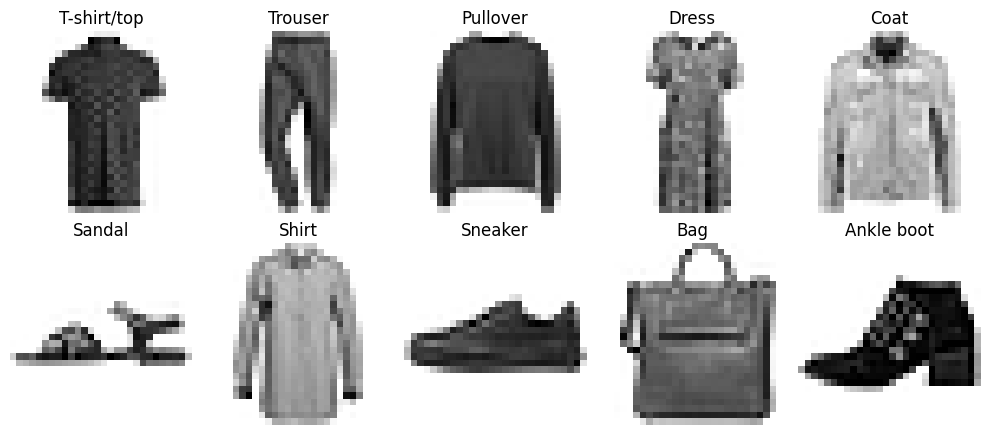

In [4]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))
for label, ax in enumerate(axes.ravel()):
    i = np.where(y == label)[0][0]
    ax.imshow(X[i].reshape(28, 28), cmap="gray_r")
    ax.set_title(class_names[label])
    ax.axis("off")
plt.tight_layout()
plt.show()

### How many images per class?

In [5]:
counts = pd.Series(y).value_counts().sort_index()
counts.index = class_names
counts

,count
T-shirt/top,2000
Trouser,2000
Pullover,2000
Dress,2000
Coat,2000
Sandal,2000
Shirt,2000
Sneaker,2000
Bag,2000
Ankle boot,2000


Every class has about 2,000 images. So:

- **Accuracy is a fair score** here. No class dominates.
- **Random guessing gives about 10%.** Any model must beat that.

### Some classes look alike

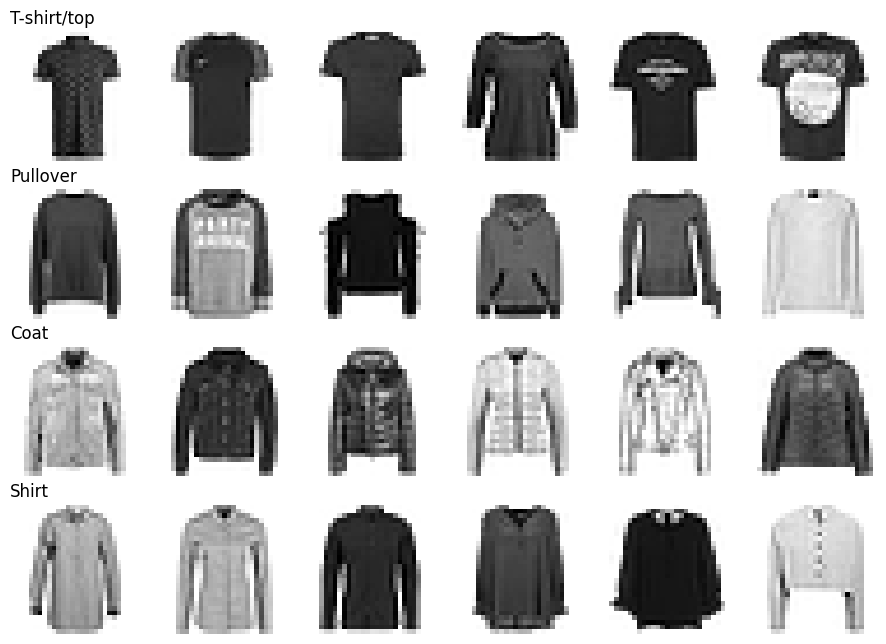

In [6]:
look_alike = [0, 2, 4, 6]   # T-shirt/top, Pullover, Coat, Shirt
fig, axes = plt.subplots(4, 6, figsize=(9, 6.5))
for row, label in enumerate(look_alike):
    idx = np.where(y == label)[0][:6]
    for col, i in enumerate(idx):
        ax = axes[row, col]
        ax.imshow(X[i].reshape(28, 28), cmap="gray_r")
        ax.axis("off")
    axes[row, 0].set_title(class_names[label], loc="left")
plt.tight_layout()
plt.show()

Tops, pullovers, coats and shirts are hard to tell apart, even for people. Expect most mistakes there. This is why no setting will reach 100%.

### Pixel values

In [7]:
print(X.min(), X.max())

0 255


Pixels go from 0 (white) to 255 (black). Networks train badly with large inputs, so we divide by 255. Now every pixel is between 0 and 1.

In [8]:
X = X / 255

## 3. Train, validation and test sets

- **Train** (14,000): the network learns from these.
- **Validation** (3,000): we compare settings on these.
- **Test** (3,000): we use these **once**, at the very end.

Why keep a test set aside? If we choose settings by looking at the test score, that score is no longer a fair estimate for new data.

In [9]:
X_train, X_rest, y_train, y_rest = train_test_split(
    X, y, train_size=14000, stratify=y, random_state=0)
X_val, X_test, y_val, y_test = train_test_split(
    X_rest, y_rest, test_size=0.5, stratify=y_rest, random_state=0)

print(len(X_train), len(X_val), len(X_test))

14000 3000 3000


## 4. Tools for the experiments

`train(...)` trains the network one epoch at a time. After each epoch it records the loss and the accuracy, on both the training and the validation set.

`compare(...)` plots several runs side by side. `results` keeps a table of every run.

You don't need to change these cells.

In [10]:
results = []

def train(label, epochs=20, learning_rate=0.01, batch_size=64,
          optimizer="sgd", momentum=0.0):
    model = MLPClassifier(hidden_layer_sizes=(64,), solver=optimizer,
                          learning_rate_init=learning_rate,
                          batch_size=batch_size, momentum=momentum,
                          random_state=0)
    classes = np.unique(y_train)
    run = {"label": label, "loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    start = time.time()
    for epoch in range(epochs):
        model.partial_fit(X_train, y_train, classes=classes)   # one epoch
        run["loss"].append(model.loss_)
        run["val_loss"].append(log_loss(y_val, model.predict_proba(X_val), labels=classes))
        run["train_acc"].append(model.score(X_train, y_train))
        run["val_acc"].append(model.score(X_val, y_val))
    seconds = time.time() - start
    run["model"] = model

    results.append({"run": label, "optimizer": optimizer,
                    "learning rate": learning_rate, "batch size": batch_size,
                    "momentum": momentum, "epochs": epochs,
                    "seconds": round(seconds, 1),
                    "train acc": round(run["train_acc"][-1], 3),
                    "val acc": round(run["val_acc"][-1], 3)})
    print(f"{label}: validation accuracy {run['val_acc'][-1]:.3f}, {seconds:.1f} s")
    return run


def compare(*runs):
    # Solid line = training set. Dashed line = validation set.
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
    for i, run in enumerate(runs):
        color = f"C{i}"
        epochs = range(1, len(run["loss"]) + 1)
        ax1.plot(epochs, run["loss"], color=color, label=run["label"])
        ax1.plot(epochs, run["val_loss"], color=color, linestyle="--")
        ax2.plot(epochs, run["train_acc"], color=color, label=run["label"])
        ax2.plot(epochs, run["val_acc"], color=color, linestyle="--")
    ax1.set(title="Loss (solid: training, dashed: validation)", xlabel="epoch", ylabel="loss")
    ax2.set(title="Accuracy (solid: training, dashed: validation)", xlabel="epoch", ylabel="accuracy")
    ax2.axhline(0.1, color="gray", linestyle=":", label="random guess")
    for ax in (ax1, ax2):
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
        ax.legend()
    plt.show()

## Which curve tells you what?

- **Training loss:** is the network learning? Falling = learning. Flat and high = stuck. Bouncing or rising = steps too big.
- **Validation accuracy:** how well it does on new data. **Use this to choose settings.**
- **Gap between training and validation:** a growing gap means overfitting.

## How to report an experiment

For every experiment, write a few lines that answer:

1. **What did you change?** And what did you keep the same?
2. **What did the numbers say?** Validation accuracy and time.
3. **What did the curves show?** Still falling, flat, bouncing, going up?
4. **What do you conclude?** One sentence, with a reason.

Example:

> I trained SGD (learning rate 0.01, batch size 64) for 60 epochs and read the curves at 5, 20 and 60 epochs. Validation accuracy rose from 0.78 to 0.83 to 0.85. The training loss was still falling slowly at epoch 60. More epochs help here, but each extra epoch helps less.

Use `pd.DataFrame(results)` to see all your numbers in one table.

## Part 1: Epochs

One epoch = one pass through all training images.

Training is the same every time (`random_state=0`). So a 5-epoch run is just the first 5 epochs of a 60-epoch run. We train once for 60 epochs and read the curve at 5, 20 and 60.

**Predict first:** how will validation accuracy change from 5 to 20 to 60 epochs?

SGD, 60 epochs: validation accuracy 0.853, 38.6 s


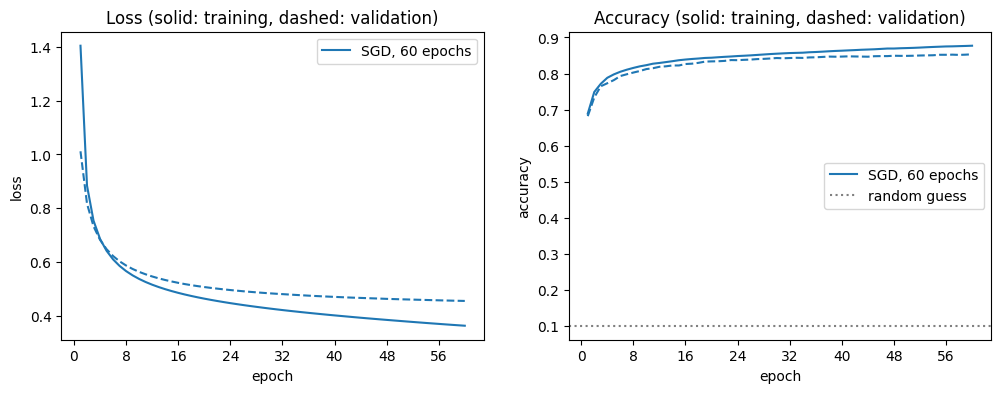

after 5 epochs: validation accuracy 0.782
after 20 epochs: validation accuracy 0.834
after 60 epochs: validation accuracy 0.853


In [11]:
e60 = train("SGD, 60 epochs", epochs=60)
compare(e60)

for e in [5, 20, 60]:
    print(f"after {e} epochs: validation accuracy {e60['val_acc'][e - 1]:.3f}")

### Too many epochs?

Adam (Part 4) learns fast. Let's train it for 60 epochs and compare training and validation accuracy.

Adam, 60 epochs: validation accuracy 0.841, 38.1 s


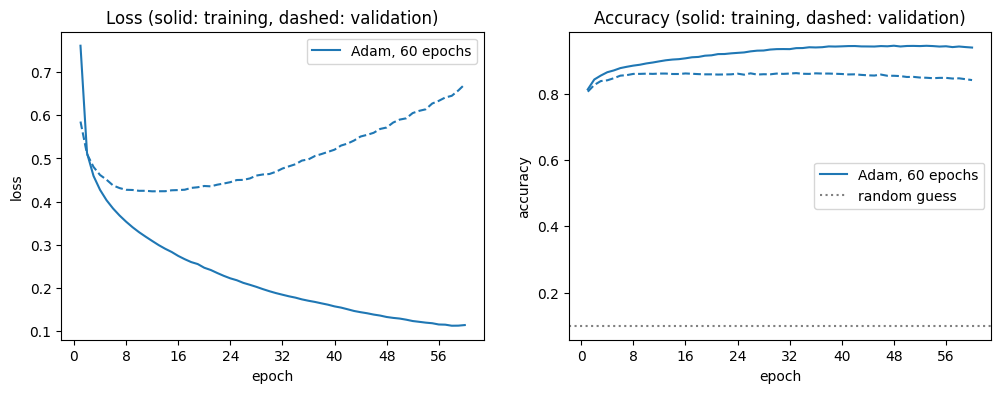

In [12]:
long = train("Adam, 60 epochs", epochs=60, optimizer="adam", learning_rate=0.001)
compare(long)

**Question:** training accuracy keeps rising. What happens to validation accuracy, and to validation loss? What does the gap tell you? *Validation accuracy is also rising but at a much slower rate than training and begins to drop off in later epochs. For the loss, the divergence is much more pronounced, especially as the number of epochs approaches 60. The training loss drops to near zero while the validation loss is increasing.*

### Early stopping

Early stopping holds out 10% of the training data. It stops when the score on that part has not improved for 5 epochs.

In [13]:
stopper = MLPClassifier(hidden_layer_sizes=(64,), solver="adam",
                        learning_rate_init=0.001, max_iter=200,
                        early_stopping=True, n_iter_no_change=5,
                        random_state=0)
stopper.fit(X_train, y_train)

print("stopped after", stopper.n_iter_, "epochs")
print("validation accuracy:", round(stopper.score(X_val, y_val), 3))

stopped after 13 epochs
validation accuracy: 0.847


**Question:** compare this with the 60-epoch Adam run. What did early stopping save you? *Early stopping scored higher becuase it prevented the validation accuracy from dropping due to training on too many epochs.*

## Part 2: Learning rate

Plain SGD, 20 epochs, batch size 64. Only the learning rate changes.

**Predict first:** which curve will be slow, which good, which broken?

lr 0.0001: validation accuracy 0.492, 12.7 s
lr 0.01: validation accuracy 0.834, 9.5 s
lr 1.0: validation accuracy 0.100, 12.5 s


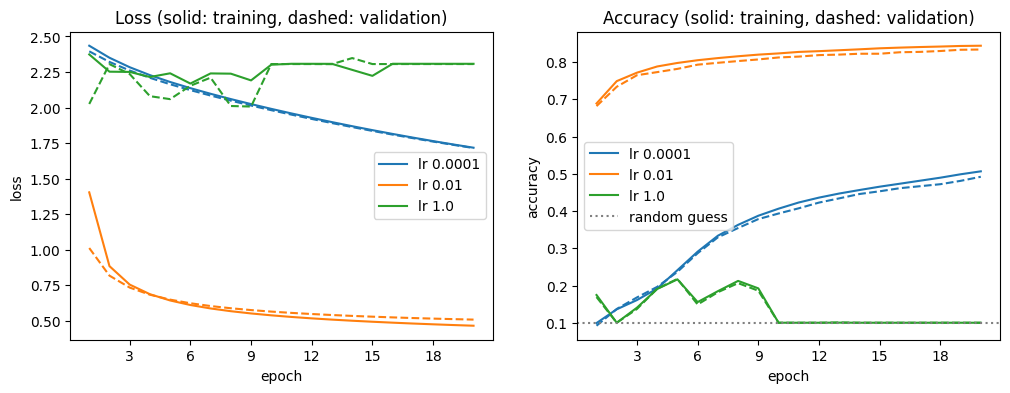

In [14]:
lr_small = train("lr 0.0001", learning_rate=0.0001)
lr_mid = train("lr 0.01", learning_rate=0.01)
lr_big = train("lr 1.0", learning_rate=1.0)
compare(lr_small, lr_mid, lr_big)

**Question:** with learning rate 1.0, the loss stays near 2.3 and validation accuracy bounces between about 10% and 20%. Random guessing among 10 classes gives a loss of about 2.3 and 10% accuracy. What does that tell you? The code is not broken: what went wrong?

## Part 3: Batch size

A **batch** is the group of training images used for one step. Sizes like 16, 64 or 128 (powers of 2) are a habit from GPU hardware; any number works. **Full batch** means all 14,000 training images in every step, so only one step per epoch.

Plain SGD, 20 epochs, learning rate 0.01. Only the batch size changes.

**Predict first:** which is fastest per epoch? Which reaches the highest accuracy in 20 epochs?

batch 16: validation accuracy 0.852, 26.5 s
batch 128: validation accuracy 0.812, 10.1 s
full batch: validation accuracy 0.381, 5.2 s


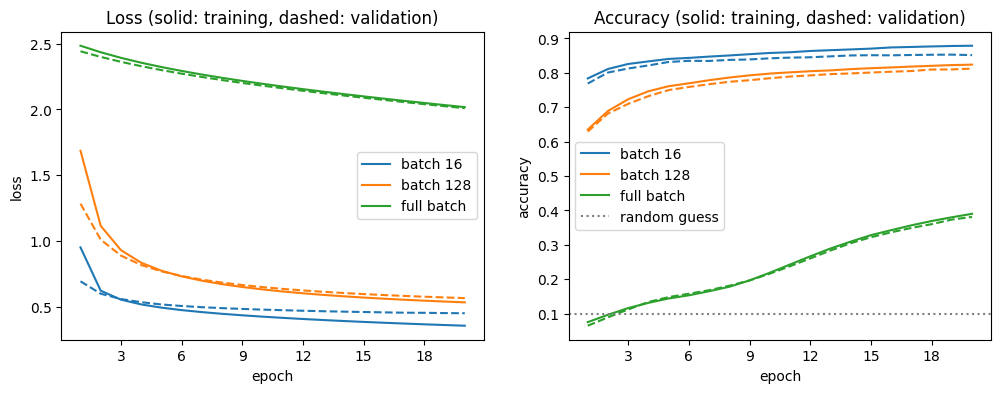

In [15]:
b16 = train("batch 16", batch_size=16)
b128 = train("batch 128", batch_size=128)
b_full = train("full batch", batch_size=14000)
compare(b16, b128, b_full)

**Question:** look at both accuracy **and** seconds. Which batch size would you choose, and why? *Batch 128 is a good middle ground between high accuracy and high speed. The full batch has much lower accuracy but is twice as fast. The batch 16 is slightly more accurte but again takes twice as long for only 4% accuracy increase.*

## Part 4: Optimizer

**Momentum** (from 0 to 1) says how much of the previous steps to keep: 0 is plain SGD, 0.9 keeps 90% of the running direction. It only works with SGD. Adam usually needs a smaller learning rate.

20 epochs, batch size 64.

SGD: validation accuracy 0.834, 12.6 s
SGD + momentum 0.9: validation accuracy 0.858, 12.8 s
Adam: validation accuracy 0.858, 14.3 s


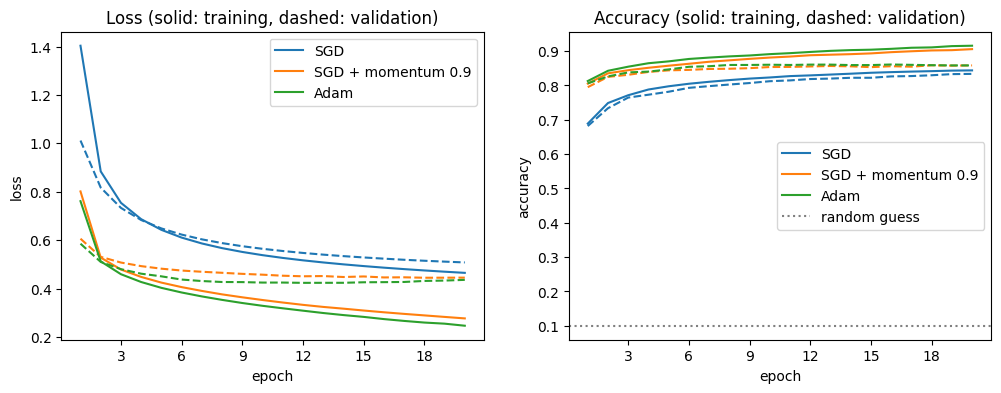

In [16]:
sgd = train("SGD", optimizer="sgd", learning_rate=0.01)
mom = train("SGD + momentum 0.9", optimizer="sgd", learning_rate=0.01, momentum=0.9)
adam = train("Adam", optimizer="adam", learning_rate=0.001)
compare(sgd, mom, adam)

**Question:** which optimizer gets to a good accuracy in the fewest epochs?

## All runs so far

In [17]:
pd.DataFrame(results)

,run,optimizer,learning rate,batch size,momentum,epochs,seconds,train acc,val acc
0,"SGD, 60 epochs",sgd,0.0100,64,0.0,60,38.6,0.877,0.853
1,"Adam, 60 epochs",adam,0.0010,64,0.0,60,38.1,0.939,0.841
2,lr 0.0001,sgd,0.0001,64,0.0,20,12.7,0.507,0.492
3,lr 0.01,sgd,0.0100,64,0.0,20,9.5,0.844,0.834
4,lr 1.0,sgd,1.0000,64,0.0,20,12.5,0.100,0.100
5,batch 16,sgd,0.0100,16,0.0,20,26.5,0.879,0.852
6,batch 128,sgd,0.0100,128,0.0,20,10.1,0.824,0.812
7,full batch,sgd,0.0100,14000,0.0,20,5.2,0.390,0.381
8,SGD,sgd,0.0100,64,0.0,20,12.6,0.844,0.834
9,SGD + momentum 0.9,sgd,0.0100,64,0.9,20,12.8,0.906,0.858


## Part 5: Your turn

Find the best settings you can.

Rules:

- Choose using **validation** accuracy only.
- Each run should take **under 60 seconds**.
- Try at least **three** settings. Change one thing at a time.

Then train your final choice and check the **test** set once.

In [18]:
# Try your settings here. Change one thing at a time.
# Example: t1 = train("my first try", optimizer="adam", learning_rate=0.001, epochs=15)

Pick your best run and check it on the test set. Do this **once**.

In [19]:
best = ...   # your chosen run, for example: best = t2
test_acc = best["model"].score(X_test, y_test)
print("validation accuracy:", round(best["val_acc"][-1], 3))
print("test accuracy:", round(test_acc, 3))

TypeError: 'ellipsis' object is not subscriptable

### Where does your model make mistakes?

In [ ]:
pred = best["model"].predict(X_test)
per_class = pd.Series([(pred[y_test == k] == k).mean() for k in range(10)],
                      index=class_names).round(3)
per_class.sort_values()

In [ ]:
wrong = np.where(pred != y_test)[0][:10]
fig, axes = plt.subplots(2, 5, figsize=(11, 5))
for ax, i in zip(axes.ravel(), wrong):
    ax.imshow(X_test[i].reshape(28, 28), cmap="gray_r")
    ax.set_title(f"true: {class_names[y_test[i]]}\npred: {class_names[pred[i]]}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

## Your report

Write a short report (5–8 lines) using the four questions from **How to report an experiment**:

- your final settings and why you chose them
- validation and test accuracy, and training time
- what the curves showed
- which classes were hardest, and why that makes sense from Section 2

*Write your report here.*